# Module 6 — Part B: VaR and stress tests

**Why this part:** the brief's learning objectives include **"Calculate VaR"** and **"Conduct stress testing"**, which no module's tasks name; they are covered here, on the four portfolios from Part A (project decision P-08, decision M6-06).

**Where this sits:** Part A built and backtested the four strategies → **Part B: how much each could lose on a bad day, a bad month, and in shocks** → Module 9 sizes the "Equity investments" bucket with these figures.

**Terms (details in `docs/documentation.md` section 9):**
- **VaR (value at risk), 95%:** the loss not exceeded on 95% of days (or months). "1-day VaR of ₹0.76 crore" = on 19 days out of 20 the loss is smaller than ₹0.76 crore.
- **CVaR (conditional VaR, expected shortfall), 95%:** the average loss on the worst 5% of days: how bad the bad days are.
- **Historical VaR:** read straight from the actual days. **Parametric VaR:** from a bell curve with the same average and swing: −(average − 1.645 × sd). 1.645 = the number of standard deviations below the average that cuts off the worst 5% of a bell curve.
- **Stress test:** the loss in a specific bad scenario, real or imagined, rather than on a "normal bad day".

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Part A's daily returns and weights |
| 2 | VaR and CVaR, 1 day and 1 month, in ₹ per ₹100 crore |
| 3 | Does the bell curve fit? Days worse than each VaR |
| 4 | Stress test (a): each strategy's worst day, month and 20-day run |
| 5 | Stress test (b): all 15 stocks fall 20% at once |
| 6 | Stress test (c): if the stocks moved together like real large-caps |
| 7 | All the risk figures in ₹, side by side |
| 8 | What the results say |
| 9 | Save the outputs |

**Decisions used:** M6-03 261-day year · M6-06 VaR and stress tests · M6-07 layout · M6-11 what Module 9 gets · M6-13 the risk table in words.

## 0. Setup
Works locally and in Google Colab. Takes under a minute. Needs Part A's outputs.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_06_portfolio_optimization"
M5_DIR = PROJECT_ROOT / "module_05_equity_markets"
IN_DIR = MODULE_DIR / "outputs" / "partA"
OUT_DIR = MODULE_DIR / "outputs" / "partB"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
sys.path.insert(0, str(M5_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from m05_data import load_market
from m06_metrics import TRADING_DAYS, RISK_FREE_ANNUAL, var_historical, var_parametric, cvar_historical, annual_volatility
from m06_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

CRORE = 100                            # results per ₹100 crore invested
LEVEL = 0.95                           # 95% VaR (decision M6-06)
Z = norm.ppf(1 - LEVEL)                # −1.645: the bell curve's 5% cut-off, in standard deviations
MONTH_DAYS = 22                        # a month ≈ 261 ÷ 12 = 21.75 trading days, rounded to whole days
RUN_DAYS = 20                          # the "worst 20-day run" (about four weeks of trading)
SHOCK = -0.20                          # stress test (b): every stock −20%
REAL_CORR = 0.4                        # stress test (c): typical correlation between Indian large-caps
EW, MK, ML, T5 = "Equal weight", "Markowitz (past returns)", "ML (ridge forecasts)", "Top 5 (Module 5)"
STRATEGIES = [EW, MK, ML, T5]
COLOURS = {EW: INK, MK: BLUE, ML: ORANGE, T5: AQUA}
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Reads from:", IN_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(f"95% VaR: bell-curve cut-off z = {Z:.3f}; month = {MONTH_DAYS} trading days")

Reads from: module_06_portfolio_optimization/outputs/partA
Outputs go to: module_06_portfolio_optimization/outputs/partB
95% VaR: bell-curve cut-off z = -1.645; month = 22 trading days


## 1. Part A's daily returns and weights

- `daily_returns.csv`: each strategy's daily return **after trading costs**, 934 days (1 Feb 2023 – 31 Aug 2026).
- `FINAL_M6_A_portfolio_weights.csv`: each strategy's weights on each of the 43 rebalance dates (used in stress tests b and c).

In [2]:
daily = pd.read_csv(IN_DIR / "daily_returns.csv", parse_dates=["Date"]).set_index("Date")[STRATEGIES]
weights = pd.read_csv(IN_DIR / "FINAL_M6_A_portfolio_weights.csv", parse_dates=["Rebalance date"])
W = {s: weights[weights.Strategy == s].pivot(index="Rebalance date", columns="Ticker", values="Weight") for s in STRATEGIES}
TICKERS = list(W[EW].columns)
mkt = load_market()
R = mkt.pivot(index="Date", columns="Ticker", values="Return").sort_index()[TICKERS]
R_test = R.loc[daily.index]                                   # the stocks' daily returns over the same 934 days
print(f"{len(daily)} days × {daily.shape[1]} strategies; {W[EW].shape[0]} rebalance dates × {len(TICKERS)} stocks")
print("Average daily return:", ", ".join(f"{s} {daily[s].mean():+.3%}" for s in STRATEGIES))
print("Daily swing (sd):    ", ", ".join(f"{s} {daily[s].std():.3%}" for s in STRATEGIES))

934 days × 4 strategies; 43 rebalance dates × 15 stocks
Average daily return: Equal weight +0.057%, Markowitz (past returns) +0.061%, ML (ridge forecasts) +0.041%, Top 5 (Module 5) +0.051%
Daily swing (sd):     Equal weight 0.482%, Markowitz (past returns) 0.730%, ML (ridge forecasts) 0.718%, Top 5 (Module 5) 0.820%


## 2. VaR and CVaR, 1 day and 1 month, in ₹ per ₹100 crore

```text
1 day, historical VaR  = the 5th-percentile daily return (the 47th-worst of 934 days), as a loss
1 day, parametric VaR  = −(average daily return − 1.645 × daily sd)
1 day, CVaR            = average loss on the days worse than the historical VaR (the worst 5%: about 47 days)
1 month (22 trading days):
    historical         = 5th percentile of every 22-day run's compounded return (913 overlapping runs)
    parametric         = −(22 × average daily − 1.645 × daily sd × √22)        (swings grow with √time)
    CVaR               = average of the 22-day runs worse than that VaR
In ₹: loss % × ₹100 crore. Example: VaR 0.76% → ₹0.76 crore
```

- **Overlapping runs:** consecutive 22-day windows share 21 days, so they are not independent; they give a smoother estimate than the 43 separate months, but count as fewer than 913 independent observations.

Losses as ₹ crore on ₹100 crore (95% level):


Strategy,"VaR 1 day, historical","VaR 1 day, parametric",CVaR 1 day,"VaR 1 month, historical","VaR 1 month, parametric",CVaR 1 month
Equal weight,₹0.76,₹0.74,₹0.98,₹1.98,₹2.47,₹2.38
Markowitz (past returns),₹1.18,₹1.14,₹1.48,₹4.05,₹4.28,₹5.24
ML (ridge forecasts),₹1.16,₹1.14,₹1.44,₹4.14,₹4.63,₹5.13
Top 5 (Module 5),₹1.29,₹1.30,₹1.62,₹5.59,₹5.21,₹6.75


Equal weight's 1-day VaR is 63% of the other strategies' average


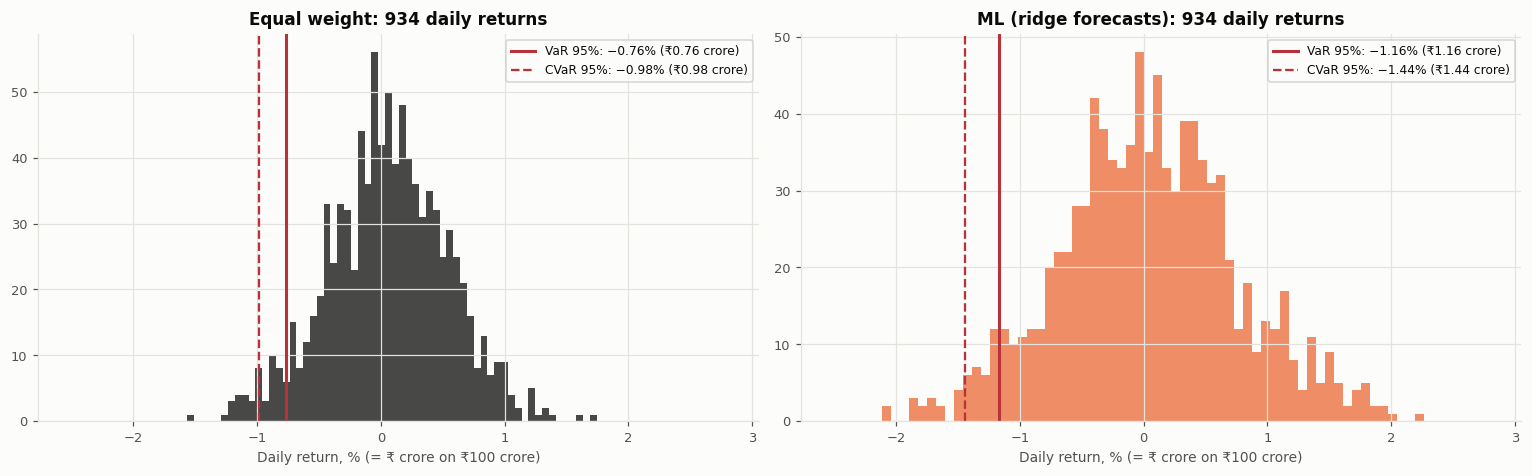

In [3]:
def run_returns(r: pd.Series, n: int) -> pd.Series:
    """Compounded return of every n-day run (overlapping windows)."""
    return (1 + r).rolling(n).apply(np.prod, raw=True).dropna() - 1


rows = []
for s in STRATEGIES:
    r = daily[s]
    m = run_returns(r, MONTH_DAYS)
    rows.append({"Strategy": s,
                 "VaR 1 day, historical": var_historical(r, LEVEL),
                 "VaR 1 day, parametric": var_parametric(r, LEVEL),
                 "CVaR 1 day": cvar_historical(r, LEVEL),
                 "VaR 1 month, historical": var_historical(m, LEVEL),
                 "VaR 1 month, parametric": -(MONTH_DAYS * r.mean() + Z * r.std() * np.sqrt(MONTH_DAYS)),
                 "CVaR 1 month": cvar_historical(m, LEVEL)})
var_table = pd.DataFrame(rows)
var_rupees = var_table.copy()
for c in var_table.columns[1:]:
    var_rupees[c] = var_table[c] * CRORE
print("Losses as ₹ crore on ₹100 crore (95% level):")
display(var_rupees.style.format({c: "₹{:.2f}" for c in var_rupees.columns[1:]}).hide(axis="index"))
print(f"Equal weight's 1-day VaR is {var_table.set_index('Strategy').loc[EW, 'VaR 1 day, historical'] / var_table['VaR 1 day, historical'].iloc[1:].mean():.0%} "
      f"of the other strategies' average")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, s in zip(axes, [EW, ML]):
    r = daily[s] * 100
    ax.hist(r, bins=60, color=COLOURS[s], alpha=0.75)
    v, cv = var_historical(daily[s]) * 100, cvar_historical(daily[s]) * 100
    ax.axvline(-v, color=LOSS, lw=2, label=f"VaR 95%: −{v:.2f}% (₹{v:.2f} crore)")
    ax.axvline(-cv, color=LOSS, lw=1.5, ls="--", label=f"CVaR 95%: −{cv:.2f}% (₹{cv:.2f} crore)")
    ax.set_xlabel("Daily return, % (= ₹ crore on ₹100 crore)")
    ax.set_title(f"{s}: 934 daily returns")
    ax.legend(fontsize=8)
axes[1].set_xlim(axes[0].get_xlim()[0] * 1.6, axes[0].get_xlim()[1] * 1.6)
axes[0].set_xlim(axes[1].get_xlim())
fig.tight_layout(); save_chart(fig, "01_daily_returns_and_var"); plt.show()

## 3. Does the bell curve fit? Days worse than each VaR

If a 95% VaR is right, about **5% of days** (about 47 of 934) should lose more than it. The historical VaR hits 5% by construction; the **parametric (bell-curve) VaR** is the real test: if returns had fatter tails than a bell curve (as real markets do), more than 5% of days would breach it.

In [4]:
fit_rows = []
for s in STRATEGIES:
    r = daily[s]
    vp = var_parametric(r, LEVEL)
    fit_rows.append({"Strategy": s, "Days worse than parametric VaR": int((r < -vp).sum()),
                     "Share of days": float((r < -vp).mean()), "Expected": 0.05,
                     "Worst day ÷ daily sd": float(-r.min() / r.std())})
fit = pd.DataFrame(fit_rows)
display(fit.style.format({"Share of days": "{:.1%}", "Expected": "{:.0%}", "Worst day ÷ daily sd": "{:.1f}"}).hide(axis="index"))
print("A bell curve rarely produces a day worse than about 3.5 sd in 934 days; real markets often show 5–10 sd days.")

Strategy,Days worse than parametric VaR,Share of days,Expected,Worst day ÷ daily sd
Equal weight,52,5.6%,5%,3.2
Markowitz (past returns),49,5.2%,5%,2.8
ML (ridge forecasts),50,5.4%,5%,2.9
Top 5 (Module 5),46,4.9%,5%,3.1


A bell curve rarely produces a day worse than about 3.5 sd in 934 days; real markets often show 5–10 sd days.


## 4. Stress test (a): each strategy's worst day, month and 20-day run

**Historical stress test:** the worst stretches that actually happened in the 934 test days, replayed on ₹100 crore.
- **Worst day.** **Worst month:** the worst of the 43 holding months (rebalance to rebalance). **Worst 20-day run:** the worst of every 20 consecutive trading days (about four weeks), wherever it starts.

**Why not the planned "replay the highest-VIX period":** VIX is the "fear index" (the market's expected swing over the next 30 days, from option prices; 10–20 calm, 30+ panic). In real markets crashes come with VIX spikes, so the highest-VIX period is a natural stress scenario. In this data VIX is random (15 different values on the same day, no link to returns), so there is no fear period to replay (decision M6-06).

In [5]:
HELD = pd.read_csv(IN_DIR / "FINAL_M6_A_portfolio_weights.csv")[["Rebalance date", "Held until"]].drop_duplicates()
month_key = pd.Series(np.searchsorted(pd.to_datetime(HELD["Rebalance date"]).values, daily.index.values, side="left") - 1,
                      index=daily.index)
stress_a = []
for s in STRATEGIES:
    r = daily[s]
    months = (1 + r).groupby(month_key.values).prod() - 1
    runs = run_returns(r, RUN_DAYS)
    stress_a.append({"Strategy": s, "Worst day": r.min(), "Worst day date": f"{r.idxmin():%d %b %Y}",
                     "Worst month": months.min(),
                     "Worst month starts": pd.to_datetime(HELD["Rebalance date"].iloc[months.idxmin()]).strftime("%d %b %Y"),
                     "Worst 20-day run": runs.min(), "Worst 20-day run ends": f"{runs.idxmin():%d %b %Y}"})
stress_a = pd.DataFrame(stress_a)
show = stress_a.copy()
for c in ["Worst day", "Worst month", "Worst 20-day run"]:
    show[c] = stress_a[c] * CRORE
print("Losses on ₹100 crore (₹ crore; negative = loss):")
display(show.style.format({c: "₹{:+.2f}" for c in ["Worst day", "Worst month", "Worst 20-day run"]}).hide(axis="index"))

Losses on ₹100 crore (₹ crore; negative = loss):


Strategy,Worst day,Worst day date,Worst month,Worst month starts,Worst 20-day run,Worst 20-day run ends
Equal weight,₹-1.57,13 May 2025,₹-3.76,31 Jan 2023,₹-4.06,01 Mar 2023
Markowitz (past returns),₹-2.08,09 Jan 2025,₹-6.15,30 Sep 2024,₹-7.03,06 Sep 2023
ML (ridge forecasts),₹-2.11,20 Feb 2023,₹-7.67,31 Jan 2023,₹-8.33,01 Mar 2023
Top 5 (Module 5),₹-2.57,16 Jun 2023,₹-7.55,31 May 2024,₹-8.37,02 Jul 2024


## 5. Stress test (b): all 15 stocks fall 20% at once

**Hypothetical stress test:** an instant market-wide fall of 20% (roughly the Nifty 50's fall over March 2020), applied to each strategy's latest weights (31 Jul 2026).

**Why not the planned "market −20% × each stock's beta":** beta = how much a stock moves when the market moves 1% (covariance with the market ÷ the market's variance); a beta shock makes high-beta stocks fall more. It needs a real market index; `Market_Return` isn't one (correlation −0.016 with the stocks' average). Measured against the equal-weight portfolio (this universe's "market"), every stock's beta is about 1 (computed below), so a beta shock is the same as every stock falling 20%.

**Note:** for any fully invested, long-only portfolio, an equal fall in every stock costs exactly that fall, whatever the weights. So this test gives the **same ₹20 crore for every strategy**: it measures exposure to a market crash, which all four have in full.

In [6]:
ew_daily = R_test.mean(axis=1)                                     # the equal-weight "market" of the 15 stocks
betas = R_test.apply(lambda x: np.cov(x, ew_daily)[0, 1] / ew_daily.var())
print(f"Each stock's beta against the equal-weight portfolio: {betas.min():.2f} to {betas.max():.2f} (average {betas.mean():.2f})")
stress_b = pd.DataFrame({"Strategy": STRATEGIES,
                         "Loss if every stock falls 20% (₹ crore)": [CRORE * float(W[s].iloc[-1] @ np.full(15, SHOCK)) for s in STRATEGIES],
                         "Loss with beta-scaled fall (₹ crore)": [CRORE * float(W[s].iloc[-1] @ (SHOCK * betas.values)) for s in STRATEGIES]})
display(stress_b.style.format({c: "₹{:+.1f}" for c in stress_b.columns[1:]}).hide(axis="index"))

Each stock's beta against the equal-weight portfolio: 0.75 to 1.21 (average 1.00)


Strategy,Loss if every stock falls 20% (₹ crore),Loss with beta-scaled fall (₹ crore)
Equal weight,₹-20.0,₹-20.0
Markowitz (past returns),₹-20.0,₹-20.9
ML (ridge forecasts),₹-20.0,₹-19.4
Top 5 (Module 5),₹-20.0,₹-19.8


## 6. Stress test (c): if the stocks moved together like real large-caps

In this data the 15 stocks move independently (average correlation 0.004, Module 5). Real Indian large-caps move together much more: typical correlations are about 0.3–0.5. When stocks move together, diversification cancels less of their swings.

```text
Portfolio swing = √(w·Σ·w),   Σ = covariance = swing of stock i × swing of stock j × correlation(i, j)
Stressed Σ: keep each stock's own swing, set every correlation to 0.4
Equal weight, rough check: one stock's swing × √(ρ + (1 − ρ) ÷ n)
    ρ = 0.004: 30% × √(0.004 + 0.996 ÷ 15) ≈ 30% × 0.27 ≈ 8%
    ρ = 0.4:   30% × √(0.4 + 0.6 ÷ 15)     ≈ 30% × 0.66 ≈ 20%
```

Each strategy's swing and 1-day / 1-month parametric VaR are computed with its weights on every rebalance date and averaged over the 43 months, first with the data's actual correlations (0.005 on average over the test days), then with 0.4.

In [7]:
vol_i = R_test.std().values                                          # each stock's daily swing over the test days
actual_corr = R_test.corr().values
stressed_corr = np.full((15, 15), REAL_CORR); np.fill_diagonal(stressed_corr, 1.0)
cov_actual = np.outer(vol_i, vol_i) * actual_corr
cov_stress = np.outer(vol_i, vol_i) * stressed_corr
DATA_CORR = actual_corr[np.triu_indices(15, 1)].mean()
print(f"Average correlation between two stocks: data {DATA_CORR:+.3f}; stressed {REAL_CORR}")
print(f"Average single stock swing: {vol_i.mean() * np.sqrt(TRADING_DAYS):.1%} a year")


def avg_daily_sd(strategy: str, cov: np.ndarray) -> float:
    """Average over the 43 rebalance dates of the portfolio's daily swing √(w·Σ·w)."""
    return float(np.mean([np.sqrt(w @ cov @ w) for w in W[strategy].values]))


stress_c = []
for s in STRATEGIES:
    mu = daily[s].mean()
    for label, cov in [(f"Data (correlation {DATA_CORR:.3f})", cov_actual), (f"Real-market (correlation {REAL_CORR})", cov_stress)]:
        sd = avg_daily_sd(s, cov)
        stress_c.append({"Strategy": s, "Correlation": label, "Volatility a year": sd * np.sqrt(TRADING_DAYS),
                         "VaR 1 day (₹ crore)": CRORE * -(mu + Z * sd),
                         "VaR 1 month (₹ crore)": CRORE * -(MONTH_DAYS * mu + Z * sd * np.sqrt(MONTH_DAYS))})
stress_c = pd.DataFrame(stress_c)
display(stress_c.style.format({"Volatility a year": "{:.1%}", "VaR 1 day (₹ crore)": "₹{:.2f}",
                               "VaR 1 month (₹ crore)": "₹{:.2f}"}).hide(axis="index"))
wide = stress_c.pivot(index="Strategy", columns="Correlation", values="Volatility a year").reindex(STRATEGIES)
wide.columns = ["data", "real"] if wide.columns[0].startswith("Data") else ["real", "data"]
ratio = (wide["real"] / wide["data"])
print("Swing multiplies by:", ", ".join(f"{s} ×{ratio[s]:.1f}" for s in STRATEGIES))

Average correlation between two stocks: data +0.005; stressed 0.4
Average single stock swing: 29.2% a year


Strategy,Correlation,Volatility a year,VaR 1 day (₹ crore),VaR 1 month (₹ crore)
Equal weight,Data (correlation 0.005),7.8%,₹0.74,₹2.47
Equal weight,Real-market (correlation 0.4),19.4%,₹1.91,₹8.00
Markowitz (past returns),Data (correlation 0.005),11.4%,₹1.10,₹4.10
Markowitz (past returns),Real-market (correlation 0.4),20.5%,₹2.02,₹8.43
ML (ridge forecasts),Data (correlation 0.005),11.2%,₹1.10,₹4.43
ML (ridge forecasts),Real-market (correlation 0.4),20.4%,₹2.04,₹8.84
Top 5 (Module 5),Data (correlation 0.005),13.1%,₹1.29,₹5.15
Top 5 (Module 5),Real-market (correlation 0.4),21.1%,₹2.10,₹8.95


Swing multiplies by: Equal weight ×2.5, Markowitz (past returns) ×1.8, ML (ridge forecasts) ×1.8, Top 5 (Module 5) ×1.6


## 7. All the risk figures in ₹, side by side

Per ₹100 crore, 95% level. Negative = loss.

Strategy,VaR 1 day,CVaR 1 day,VaR 1 month,Worst day,Worst month,Worst 20-day run,All stocks −20%,"VaR 1 month, real-market correlation"
Equal weight,₹-0.76,₹-0.98,₹-1.98,₹-1.57,₹-3.76,₹-4.06,₹-20.00,₹-8.00
Markowitz (past returns),₹-1.18,₹-1.48,₹-4.05,₹-2.08,₹-6.15,₹-7.03,₹-20.00,₹-8.43
ML (ridge forecasts),₹-1.16,₹-1.44,₹-4.14,₹-2.11,₹-7.67,₹-8.33,₹-20.00,₹-8.84
Top 5 (Module 5),₹-1.29,₹-1.62,₹-5.59,₹-2.57,₹-7.55,₹-8.37,₹-20.00,₹-8.95


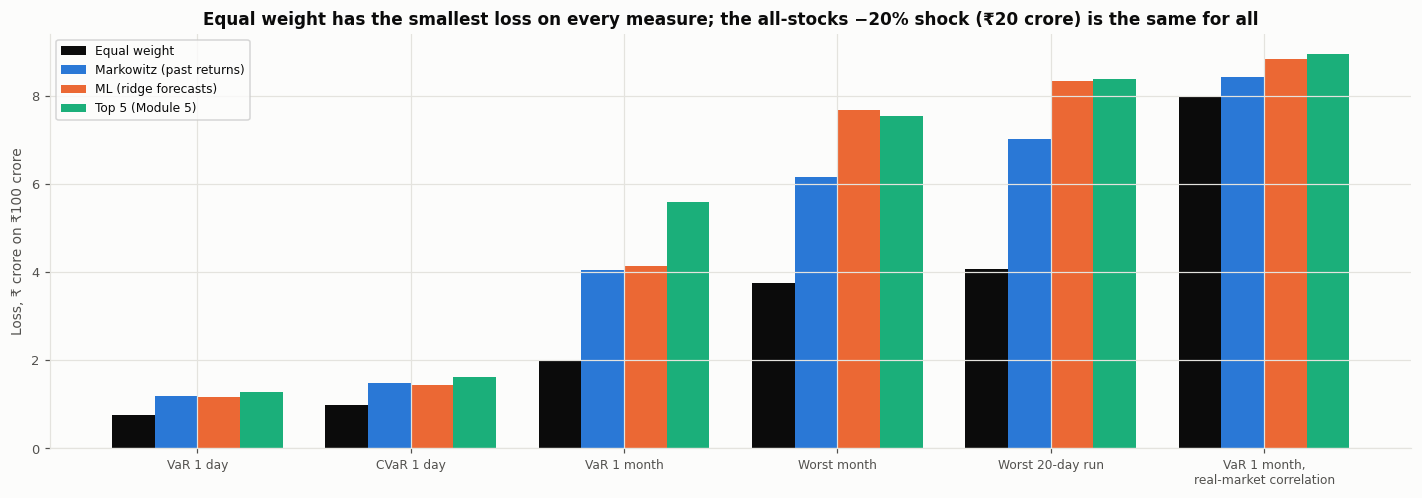

In [8]:
summary = pd.DataFrame({"Strategy": STRATEGIES})
vt = var_table.set_index("Strategy")
sa = stress_a.set_index("Strategy")
sc = stress_c.set_index(["Strategy", "Correlation"])
real_label = f"Real-market (correlation {REAL_CORR})"
summary["VaR 1 day"] = [-CRORE * vt.loc[s, "VaR 1 day, historical"] for s in STRATEGIES]
summary["CVaR 1 day"] = [-CRORE * vt.loc[s, "CVaR 1 day"] for s in STRATEGIES]
summary["VaR 1 month"] = [-CRORE * vt.loc[s, "VaR 1 month, historical"] for s in STRATEGIES]
summary["Worst day"] = [CRORE * sa.loc[s, "Worst day"] for s in STRATEGIES]
summary["Worst month"] = [CRORE * sa.loc[s, "Worst month"] for s in STRATEGIES]
summary["Worst 20-day run"] = [CRORE * sa.loc[s, "Worst 20-day run"] for s in STRATEGIES]
summary["All stocks −20%"] = stress_b["Loss if every stock falls 20% (₹ crore)"].values
summary["VaR 1 month, real-market correlation"] = [-sc.loc[(s, real_label), "VaR 1 month (₹ crore)"] for s in STRATEGIES]
display(summary.style.format({c: "₹{:+.2f}" for c in summary.columns[1:]}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(13, 4.6))
cols = ["VaR 1 day", "CVaR 1 day", "VaR 1 month", "Worst month", "Worst 20-day run", "VaR 1 month, real-market correlation"]
x = np.arange(len(cols)); width = 0.2
for i, s in enumerate(STRATEGIES):
    ax.bar(x + (i - 1.5) * width, -summary.set_index("Strategy").loc[s, cols], width, color=COLOURS[s], label=s)
ax.set_xticks(x); ax.set_xticklabels([c.replace(", real-market", ",\nreal-market") for c in cols], fontsize=8)
ax.set_ylabel("Loss, ₹ crore on ₹100 crore")
ax.set_title("Equal weight has the smallest loss on every measure; the all-stocks −20% shock (₹20 crore) is the same for all")
ax.legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "02_risk_in_rupees"); plt.show()

## 8. What the results say

**Answer for Part B: equal weight has the smallest loss on every risk measure, except a 20% fall in all stocks, which costs every strategy the same. But this data understates real risk: if the stocks moved together like real large-caps, equal weight's yearly swing would be about 2.5 times larger (7.8% → 19.4%), and its lead over the other strategies would mostly disappear.**

**Reminder:** VaR 95% = the loss not exceeded on 95% of days (or months); CVaR = the average loss on the worst 5%. All figures per ₹100 crore.

### All the risk figures (₹ crore lost on ₹100 crore)

| Strategy | VaR 1 day | CVaR 1 day | VaR 1 month | Worst day | Worst month | Worst 20-day run | Every stock −20% | VaR 1 month, real-market correlation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Equal weight** | **₹0.76** | **₹0.98** | **₹1.98** | **₹1.57** | **₹3.76** | **₹4.06** | ₹20.0 | **₹8.00** |
| Markowitz (past returns) | ₹1.18 | ₹1.48 | ₹4.05 | ₹2.08 | ₹6.15 | ₹7.03 | ₹20.0 | ₹8.43 |
| ML (ridge forecasts) | ₹1.16 | ₹1.44 | ₹4.14 | ₹2.11 | ₹7.67 | ₹8.33 | ₹20.0 | ₹8.84 |
| Top 5 (Module 5) | ₹1.29 | ₹1.62 | ₹5.59 | ₹2.57 | ₹7.55 | ₹8.37 | ₹20.0 | ₹8.95 |

- **VaR and CVaR (step 2):** on 19 days in 20, equal weight loses less than ₹0.76 crore; on the worst 1 day in 20 it loses ₹0.98 crore on average. The others lose 1.5–1.7 times as much (₹1.16 ÷ ₹0.76 = 1.5 to ₹1.29 ÷ ₹0.76 = 1.7).

```text
Equal weight's VaR as a share of the other three's average:
  1 day:   ₹0.76 ÷ [(₹1.18 + ₹1.16 + ₹1.29) ÷ 3 = ₹1.21] = 63%
  1 month: ₹1.98 ÷ [(₹4.05 + ₹4.14 + ₹5.59) ÷ 3 = ₹4.59] = 43%
```
- **Historical (actual days) and parametric (bell curve) VaR agree closely** (e.g. equal weight ₹0.76 vs ₹0.74 crore a day). **The bell curve fits (step 3):** 4.9%–5.6% of days were worse than the parametric VaR (5% expected), and the worst day was only 2.8–3.2 standard deviations below average. Real markets have fatter tails (days of 5–10 standard deviations), so real VaR would be larger.

### Stress tests

- **(a) Historical worst stretches:** equal weight's worst month cost ₹3.76 crore (Feb 2023) and its worst 20-day run ₹4.06 crore, against ₹6–8 crore for the others.
- **(b) Every stock −20% at once: ₹20 crore for every strategy.** Any fully invested, long-only portfolio loses exactly the fall when every stock falls equally, whatever its weights. The beta-scaled version gives ₹19.4–20.9 crore: the stocks' betas against the equal-weight portfolio are 0.75–1.21 (average 1.00), so it barely differs. This is the loss that diversification can't protect against: only holding less equity (or hedging, Module 8) reduces it.
- **(c) Real-market correlation (0.4 instead of 0.005):**

| Strategy | Yearly swing: data | Real-market | Multiplied by |
| --- | --- | --- | --- |
| Equal weight | 7.8% | 19.4% | ×2.5 |
| Markowitz (past returns) | 11.4% | 20.5% | ×1.8 |
| ML (ridge forecasts) | 11.2% | 20.4% | ×1.8 |
| Top 5 (Module 5) | 13.1% | 21.1% | ×1.6 |

  - **Equal weight's low risk in this data comes from the stocks being independent.** When stocks move together, spreading evenly cancels much less of their swings, so its risk rises most (×2.5).
  - **All four strategies end up close:** 19.4%–21.1% a year; 1-month VaR ₹8.00–8.95 crore. Equal weight stays lowest, but its lead shrinks:

```text
Yearly swing: 7.8% (data) → 19.4% (real-market) = × 2.5  (19.4 ÷ 7.8)
Equal weight's 1-month parametric VaR as a share of the other three's average:
  data:        ₹2.47 ÷ [(₹4.10 + ₹4.43 + ₹5.15) ÷ 3 = ₹4.56] = 54%
  real-market: ₹8.00 ÷ [(₹8.43 + ₹8.84 + ₹8.95) ÷ 3 = ₹8.74] = 92%
```

### What it means for the committee and Module 9
1. **Equal weight is the lowest-risk strategy on every measure except a 20% fall in all stocks (the same for all),** in this data and under real-market correlation.
2. **Plan with real-market risk, not this data's:** equal weight's yearly swing of 7.8% here would be about 19% with real co-movement; 1-month VaR about ₹8 crore per ₹100 crore, not ₹2 crore.
3. **A market-wide crash can't be diversified away:** a 20% fall costs ₹20 crore per ₹100 crore in any of these portfolios. Limits on the equity allocation (Module 9) and hedging (Module 8) are the controls for it.

## 9. Save the outputs

- **`FINAL_M6_B_risk_summary.csv`: every risk figure, one row per strategy and measure, in words** (decision M6-13): value, unit, basis (actual days / bell curve / stress scenario), rank among the 4 strategies, and what it means. It feeds the Module 6 workbook and its Module 9 hand-off.
- **`var_table.csv`** (step 2) and **`stress_tests.csv`** (steps 4–6, one row per strategy and test).
- The charts above and `key_numbers.json`.

In [9]:
RANK_WORDS = {1: "the lowest of the 4 strategies", 2: "2nd lowest of 4", 3: "3rd lowest of 4", 4: "the highest of the 4 strategies"}
vt, sa_ = var_table.set_index("Strategy"), stress_a.set_index("Strategy")
sb, sc_ = stress_b.set_index("Strategy"), stress_c.set_index(["Strategy", "Correlation"])
data_label = [c for c in stress_c.Correlation.unique() if c.startswith("Data")][0]
MEASURES = [
    # (measure, unit, basis, value function (loss on ₹100 crore, positive), sentence template)
    ("VaR 95%, 1 day", "₹ crore per ₹100 crore", "Actual days", lambda s: CRORE * vt.loc[s, "VaR 1 day, historical"],
     "On 19 trading days in 20, ₹100 crore in {s} loses less than ₹{v:.2f} crore"),
    ("VaR 95%, 1 day (bell curve)", "₹ crore per ₹100 crore", "Bell curve", lambda s: CRORE * vt.loc[s, "VaR 1 day, parametric"],
     "A bell curve with {s}'s average and swing puts the 1-in-20 daily loss at ₹{v:.2f} crore"),
    ("CVaR 95%, 1 day", "₹ crore per ₹100 crore", "Actual days", lambda s: CRORE * vt.loc[s, "CVaR 1 day"],
     "On the worst 1 day in 20, ₹100 crore in {s} loses ₹{v:.2f} crore on average"),
    ("VaR 95%, 1 month", "₹ crore per ₹100 crore", "Actual 22-day runs", lambda s: CRORE * vt.loc[s, "VaR 1 month, historical"],
     "In 19 months out of 20, ₹100 crore in {s} loses less than ₹{v:.2f} crore"),
    ("VaR 95%, 1 month (bell curve)", "₹ crore per ₹100 crore", "Bell curve", lambda s: CRORE * vt.loc[s, "VaR 1 month, parametric"],
     "A bell curve puts {s}'s 1-in-20 monthly loss at ₹{v:.2f} crore"),
    ("CVaR 95%, 1 month", "₹ crore per ₹100 crore", "Actual 22-day runs", lambda s: CRORE * vt.loc[s, "CVaR 1 month"],
     "In the worst 1 month in 20, ₹100 crore in {s} loses ₹{v:.2f} crore on average"),
    ("Worst day", "₹ crore per ₹100 crore", "Actual days", lambda s: -CRORE * sa_.loc[s, "Worst day"],
     "{s}'s worst single day in the test period cost ₹{v:.2f} crore on ₹100 crore"),
    ("Worst month", "₹ crore per ₹100 crore", "Actual months", lambda s: -CRORE * sa_.loc[s, "Worst month"],
     "{s}'s worst holding month cost ₹{v:.2f} crore on ₹100 crore"),
    ("Worst 20-day run", "₹ crore per ₹100 crore", "Actual days", lambda s: -CRORE * sa_.loc[s, "Worst 20-day run"],
     "{s}'s worst 20 consecutive trading days cost ₹{v:.2f} crore on ₹100 crore"),
    ("Every stock falls 20%", "₹ crore per ₹100 crore", "Stress scenario", lambda s: -sb.loc[s, "Loss if every stock falls 20% (₹ crore)"],
     "If every stock fell 20% at once, ₹100 crore in {s} would lose ₹{v:.1f} crore: the same for every fully invested portfolio, so diversification can't reduce it"),
    ("Beta-scaled 20% fall", "₹ crore per ₹100 crore", "Stress scenario", lambda s: -sb.loc[s, "Loss with beta-scaled fall (₹ crore)"],
     "If the fall followed each stock's beta (0.75–1.21 against the equal-weight portfolio), ₹100 crore in {s} would lose ₹{v:.1f} crore"),
    ("VaR 95%, 1 day, real-market correlation", "₹ crore per ₹100 crore", "Stress scenario (correlation 0.4)",
     lambda s: sc_.loc[(s, real_label), "VaR 1 day (₹ crore)"],
     "If the stocks moved together like real large-caps, on 19 days in 20 ₹100 crore in {s} would lose less than ₹{v:.2f} crore"),
    ("VaR 95%, 1 month, real-market correlation", "₹ crore per ₹100 crore", "Stress scenario (correlation 0.4)",
     lambda s: sc_.loc[(s, real_label), "VaR 1 month (₹ crore)"],
     "If the stocks moved together like real large-caps, in 19 months out of 20 ₹100 crore in {s} would lose less than ₹{v:.2f} crore"),
    ("Yearly swing (volatility), this data", "% a year", "Actual days (weights averaged over 43 months)",
     lambda s: 100 * sc_.loc[(s, data_label), "Volatility a year"],
     "{s}'s returns typically move about ±{v:.1f}% in a year in this data, where the stocks move independently"),
    ("Yearly swing (volatility), real-market correlation", "% a year", "Stress scenario (correlation 0.4)",
     lambda s: 100 * sc_.loc[(s, real_label), "Volatility a year"],
     "If the stocks moved together like real large-caps, {s}'s returns would typically move about ±{v:.1f}% in a year"),
]
long_rows = []
for measure, unit, basis, fn, sentence in MEASURES:
    vals = {s: float(fn(s)) for s in STRATEGIES}
    order = pd.Series(vals).rank(method="min").astype(int)
    for s in STRATEGIES:
        long_rows.append({"Strategy": s, "Measure": measure, "Value": vals[s], "Unit": unit, "Basis": basis,
                          "Rank among the 4 (1 = smallest)": int(order[s]),
                          "What it means, in words": sentence.format(s=s, v=vals[s]) + f"; {RANK_WORDS[int(order[s])]}."})
risk_long = pd.DataFrame(long_rows)
risk_long.loc[risk_long.Measure == "Every stock falls 20%", "What it means, in words"] = [
    sentence.format(s=s, v=20.0) + "." for s, sentence in zip(STRATEGIES, [MEASURES[9][4]] * 4)]
risk_long.loc[risk_long.Measure == "Every stock falls 20%", "Rank among the 4 (1 = smallest)"] = 1
save_table(risk_long.round(4), "FINAL_M6_B_risk_summary")
print(f"Risk table: {len(risk_long)} rows = {len(STRATEGIES)} strategies × {len(MEASURES)} measures")
print(risk_long[(risk_long.Strategy == EW) & (risk_long.Measure == "VaR 95%, 1 month, real-market correlation")].iloc[0]["What it means, in words"])
save_table(var_table.round(6), "var_table")
st = []
for _, r in stress_a.iterrows():
    for c, when in [("Worst day", "Worst day date"), ("Worst month", "Worst month starts"), ("Worst 20-day run", "Worst 20-day run ends")]:
        st.append({"Strategy": r.Strategy, "Test": f"(a) {c}", "Loss on ₹100 crore": CRORE * r[c], "When": r[when]})
for _, r in stress_b.iterrows():
    st.append({"Strategy": r.Strategy, "Test": "(b) Every stock −20%", "Loss on ₹100 crore": r["Loss if every stock falls 20% (₹ crore)"], "When": "Hypothetical"})
for _, r in stress_c.iterrows():
    st.append({"Strategy": r.Strategy, "Test": f"(c) VaR 1 month, {r.Correlation}", "Loss on ₹100 crore": -r["VaR 1 month (₹ crore)"], "When": "Hypothetical"})
save_table(pd.DataFrame(st).round(4), "stress_tests")


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


key = {"level": LEVEL, "month_days": MONTH_DAYS, "real_corr": REAL_CORR, "beta_range": [r4(betas.min()), r4(betas.max())],
       "summary": {r.Strategy: {c: r4(r[c]) for c in summary.columns[1:]} for _, r in summary.iterrows()},
       "vol_data_vs_real": {s: [r4(wide.loc[s, "data"]), r4(wide.loc[s, "real"])] for s in STRATEGIES},
       "parametric_breach_share": {r.Strategy: r4(r["Share of days"]) for _, r in fit.iterrows()}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Risk table: 60 rows = 4 strategies × 15 measures
If the stocks moved together like real large-caps, in 19 months out of 20 ₹100 crore in Equal weight would lose less than ₹8.00 crore; the lowest of the 4 strategies.
Saved to module_06_portfolio_optimization/outputs/partB
['01_daily_returns_and_var.png', '02_risk_in_rupees.png', 'FINAL_M6_B_risk_summary.csv', 'key_numbers.json', 'stress_tests.csv', 'var_table.csv']


## What goes to Module 9: equities in the standard fields (decision M6-14)
Module 9 compares every business on the same fields. Equities: Part A's return after costs and its 95% range, and Part B's real-market risk: the 1-in-20 year at the real-market swing, and the crash loss diversification can't remove.

In [10]:
M9_COLS = ["Category", "What NovaFin would put money into", "Return per ₹ deployed (% a year)", "Return range (% a year)",
           "Bad-year result per ₹ (% a year)", "How the bad year is defined", "Capacity (₹ crore)", "Evidence strength",
           "How fast the money can come back", "Data gap or assumption", "Controls", "Detail tab", "Detail column(s)", "Decision"]
KA = json.loads((MODULE_DIR / "outputs" / "partA" / "key_numbers.json").read_text(encoding="utf-8"))
daily_ = pd.read_csv(MODULE_DIR / "outputs" / "partA" / "daily_returns.csv", parse_dates=["Date"]); r_ = daily_["Equal weight"]
ret = 100 * float((1 + r_).prod() ** (261 / len(r_)) - 1)
mon = (1 + r_).groupby(daily_.Date.dt.to_period("M")).prod() - 1
half = 100 * 1.96 * mon.std(ddof=1) / np.sqrt(len(mon)) * 12
swing = 100 * json.loads((OUT_DIR / "key_numbers.json").read_text(encoding="utf-8"))["vol_data_vs_real"]["Equal weight"][1]
bad = ret - 1.645 * swing
m9_inputs = pd.DataFrame([{"Category": "Equity investments (equal weight, 15 stocks)", "What NovaFin would put money into": "All 15 stocks at equal weight, reset monthly",
    "Return per ₹ deployed (% a year)": round(ret, 2), "Return range (% a year)": f"{ret - half:.1f} to {ret + half:.1f} (95% range of the measured return)",
    "Bad-year result per ₹ (% a year)": round(bad, 2), "How the bad year is defined": f"1-in-20 year at the real-market swing ({swing:.1f}%): return − 1.645 × swing; a crash (all stocks −20%) loses 20%",
    "Capacity (₹ crore)": "Large (listed stocks)", "Evidence strength": "Medium: 43 test months; real-market risk is a stress estimate (correlation 0.4)",
    "How fast the money can come back": "Days (listed stocks)", "Data gap or assumption": "Stocks in the data move independently, so measured risk understates the real one; no dividends",
    "Controls": "Equal weight, monthly reset; VaR limit (₹8 crore a month per ₹100 crore); crash protection with a put (Module 8)",
    "Detail tab": "A daily returns, B risk summary", "Detail column(s)": "Equal weight; Yearly swing (real-market)", "Decision": "M6-14"}])[M9_COLS]
m9_inputs.to_csv(OUT_DIR / "module9_inputs.csv", index=False)
print(f"Equities: {ret:.1f}% a year (range {ret - half:.1f}–{ret + half:.1f}); 1-in-20 year {bad:.1f}%; crash −20%")
display(m9_inputs.T)

Equities: 15.6% a year (range 8.6–22.6); 1-in-20 year -16.2%; crash −20%


,0
Category,"Equity investments (equal weight, 15 stocks)"
What NovaFin would put money into,"All 15 stocks at equal weight, reset monthly"
Return per ₹ deployed (% a year),15.6
Return range (% a year),8.6 to 22.6 (95% range of the measured return)
Bad-year result per ₹ (% a year),-16.24
How the bad year is defined,1-in-20 year at the real-market swing (19.4%):...
Capacity (₹ crore),Large (listed stocks)
Evidence strength,Medium: 43 test months; real-market risk is a ...
How fast the money can come back,Days (listed stocks)
Data gap or assumption,"Stocks in the data move independently, so meas..."
